# Testing performance of optimized heterogeneous vs homogenous DDNs and ESNs
Taking the best networks from the optimization runs from april 2025

First, import the validation results

In [1]:
import pickle

import numpy as np
import pickle as pkl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import cma
from pathlib import Path
print(cma.__version__)
def load_results_dict(dir, filename):
    with open(dir+'/'+filename, 'rb') as f:
        results = pkl.load(f)
    return results

multitask = False
max_gen = 200
dir = 'heterogeneity_results_MG/'

# MG_imports = {
#     'ddn': {
#         'distributed': {
#             'cluster': {'path': dir + '2026-03-26_DDN_dist_decay_per_cluster_variable_tau.p'},
#             'network': {'path': dir +'2026-03-26_DDN_dist_decay_net_wide_variable_tau.p'},
#         },
#         'fixed': {
#             'cluster': {'path': dir +'2026-03-26_DDN_fixed_decay_per_cluster_variable_tau.p'},
#             'network': {'path': dir +'2026-03-26_DDN_fixed_decay_net_wide_variable_tau.p'},
#         }
#     },
#     'esn': {
#         'distributed': {
#             'cluster': {'path': dir +'2026-03-27_BL_dist_decay_per_cluster_variable_tau.p'},
#             'network': {'path': dir +'2026-03-27_BL_dist_decay_net_wide_variable_tau.p'},
#         },
#         'fixed': {
#             'cluster': {'path': dir +'2026-03-26_BL_fixed_decay_per_cluster_variable_tau.p'},
#             'network': {'path': dir +'2026-03-26_BL_fixed_decay_net_wide_variable_tau.p'},
#         }
#     }
# }

MG_imports = {
    'ddn': {
        'distributed': {
            'cluster': {'path': dir + '2025-04-24_DDN_dist_decay_per_cluster.p'},
            'network': {'path': dir +'2025-04-24_DDN_dist_decay_net_wide.p'},
        },
        'fixed': {
            'cluster': {'path': dir +'2025-04-24_DDN_fixed_decay_per_cluster.p'},
            'network': {'path': dir +'2025-04-24_DDN_fixed_decay_net_wide.p'},
        }
    },
    'esn': {
        'distributed': {
            'cluster': {'path': dir +'2025-04-24_BL_dist_decay_per_cluster.p'},
            'network': {'path': dir +'2025-04-29_BL_dist_decay_net_wide.p'},
        },
        'fixed': {
            'cluster': {'path': dir +'2025-04-24_BL_fixed_decay_per_cluster.p'},
            'network': {'path': dir +'2025-04-24_BL_fixed_decay_net_wide.p'},
        }
    }
}
for net_type in MG_imports:
    for heterogeneity in MG_imports[net_type]:
        for het_type in MG_imports[net_type][heterogeneity]:
            path_str = MG_imports[net_type][heterogeneity][het_type]["path"] 
            MG_imports[net_type][heterogeneity][het_type]["path"] = Path(path_str) 

3.2.2


In [2]:
for net_type in MG_imports:
    for heterogeneity in MG_imports[net_type]:
        for het_type in MG_imports[net_type][heterogeneity]:

            with open(MG_imports[net_type][heterogeneity][het_type]['path'], 'rb') as f:
                MG_imports[net_type][heterogeneity][het_type]['results_dict'] = pkl.load(f)
                print(MG_imports[net_type][heterogeneity][het_type]['results_dict'].keys())
                print(MG_imports[net_type][heterogeneity][het_type]['results_dict']['alpha grid'])

dict_keys(['validation performance', 'parameters', 'evolutionary strategy', 'cma stds', 'error margin', 'number of sequences', 'number of samples', 'alpha grid', 'tau range', 'start value range', 'example net'])
[1e-08, 1e-06, 0.0001, 0.01, 1]
dict_keys(['validation performance', 'parameters', 'evolutionary strategy', 'cma stds', 'error margin', 'number of sequences', 'number of samples', 'alpha grid', 'tau range', 'start value range', 'example net'])
[1e-08, 1e-06, 0.0001, 0.01, 1]
dict_keys(['validation performance', 'parameters', 'evolutionary strategy', 'cma stds', 'error margin', 'number of sequences', 'number of samples', 'alpha grid', 'tau range', 'start value range', 'example net'])
[1e-08, 1e-06, 0.0001, 0.01, 1]
dict_keys(['validation performance', 'parameters', 'evolutionary strategy', 'cma stds', 'error margin', 'number of sequences', 'number of samples', 'alpha grid', 'tau range', 'start value range', 'example net'])
[1e-08, 1e-06, 0.0001, 0.01, 1]
dict_keys(['validation p

Plot evolution plots, to see how validation throughout evolution for all experiment conditions

In [3]:
def MG_plot_df_from_evo_dict(res_dict, max_gen):
    df_dict = {
        'Generation' : [],
        'Prediction Horizon' : [],
        'Tau': []
    }
    dict_keys = list(res_dict.keys())
    if 'tau_list' in dict_keys:
        tau_list = res_dict['tau list']
    else:
        tau_list = [17] * 5
    best_i = np.argmax(np.mean(res_dict['validation performance'][:max_gen, :, :], axis=-1), axis=-1)
    plot = []
    for ind, i in enumerate(best_i):
        plot.append(res_dict['validation performance'][ind, i, :])
    plot = np.array(plot)

    for gen, pop in enumerate(plot):
        df_dict['Generation'] += list(np.repeat(gen, pop.shape))
        df_dict['Prediction Horizon'] += list(pop)
        df_dict['Tau'] += tau_list
    df_plot = pd.DataFrame.from_dict(df_dict)
    return df_plot

In [4]:
for net_type in MG_imports:
    for heterogeneity in MG_imports[net_type]:
        for het_type in MG_imports[net_type][heterogeneity]:
            dict = MG_imports[net_type][heterogeneity][het_type]['results_dict']
            plot_df = MG_plot_df_from_evo_dict(dict, max_gen)
            MG_imports[net_type][heterogeneity][het_type]['evo_df'] = plot_df

[]

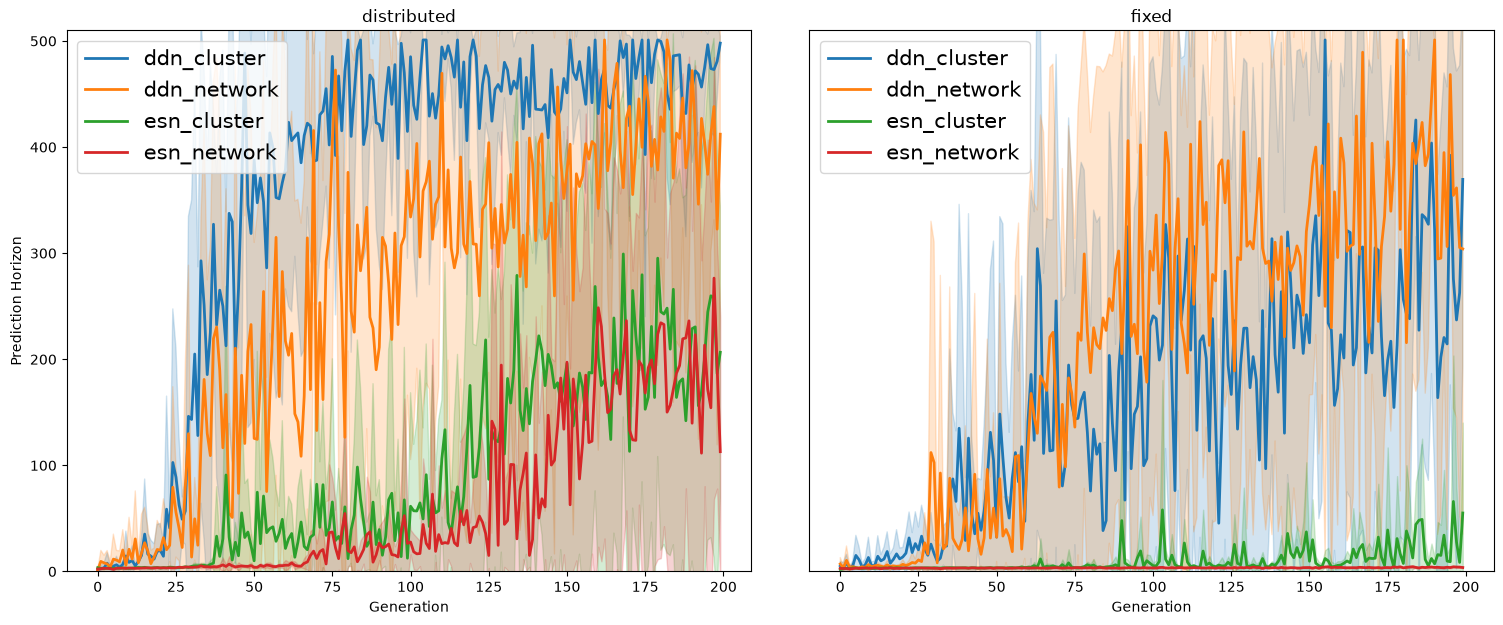

In [5]:
fig, ax= plt.subplots(1, 2, figsize=(15,6))
plt.tight_layout()
for net_type in MG_imports:
    for sp, heterogeneity in enumerate(MG_imports[net_type]):
        ax[sp].set_title(heterogeneity)
        ax[sp].set_ylim(0, 510)

        for het_type in MG_imports[net_type][heterogeneity]:
            df_to_plot = MG_imports[net_type][heterogeneity][het_type]['evo_df']
            
            plot_name = net_type + "_" + het_type
            sns.lineplot(df_to_plot, x='Generation', y='Prediction Horizon', ax=ax[sp], linewidth=2, linestyle="-",label=plot_name, errorbar='sd')

ax[0].legend(fontsize=15)
ax[1].legend(fontsize=15)
ax[1].set_ylabel(None)
ax[1].set_yticks([])

Now let's have a look at the best networks and compare their validation scores. Note that for these results, we don't know on which tau they were evaluated

In [6]:
def get_best_net_info(evo_dict):
    val_scores = evo_dict["validation performance"]
    val_scores_av = np.mean(val_scores, axis=-1)
    best_inds = np.argmax(val_scores_av, axis=-1)
    best_scores = val_scores_av[np.arange(len(best_inds)), best_inds]
    best_gen = np.argmax(best_scores)
    best_val_results = val_scores[best_gen, best_inds[best_gen], :]
    return best_gen, best_inds[best_gen], best_val_results

In [7]:
best_val_results_bl = {
    "Score": [],
    "Heterogeneity": [],
    "Het type": []
}

best_val_results_ddn = {
    "Score": [],
    "Heterogeneity": [],
    "Het type": []
}

for heterogeneity in MG_imports["esn"]:
    for het_type in MG_imports["esn"][heterogeneity]:
        r_dict = MG_imports["esn"][heterogeneity][het_type]['results_dict']
        best_g, best_i, best_val = get_best_net_info(r_dict)
        print(best_g, best_i, best_val)

        best_val_results_bl["Score"] += list(best_val)
        best_val_results_bl["Heterogeneity"] += [heterogeneity] * len(best_val)
        best_val_results_bl["Het type"] += [het_type] * len(best_val)

for heterogeneity in MG_imports["ddn"]:
    for het_type in MG_imports["ddn"][heterogeneity]:
        r_dict = MG_imports["ddn"][heterogeneity][het_type]['results_dict']
        best_g, best_i, best_val = get_best_net_info(r_dict)
        print(best_g, best_i, best_val)

        best_val_results_ddn["Score"] += list(best_val)
        best_val_results_ddn["Heterogeneity"] += [heterogeneity] * len(best_val)
        best_val_results_ddn["Het type"] += [het_type] * len(best_val)


168 8 [218.8 184.2 501.  166.  426.4]
197 0 [501.  449.8 289.  137.8   5. ]
196 11 [312.    2.8   4.4   8.    3. ]
183 14 [6.6 3.2 5.6 3.8 3. ]
80 14 [501. 501. 501. 501. 501.]
162 12 [501. 501. 501. 501. 501.]
155 16 [501. 501. 501. 501. 501.]
178 6 [501. 501. 501. 501. 501.]


(-100.0, 550.0)

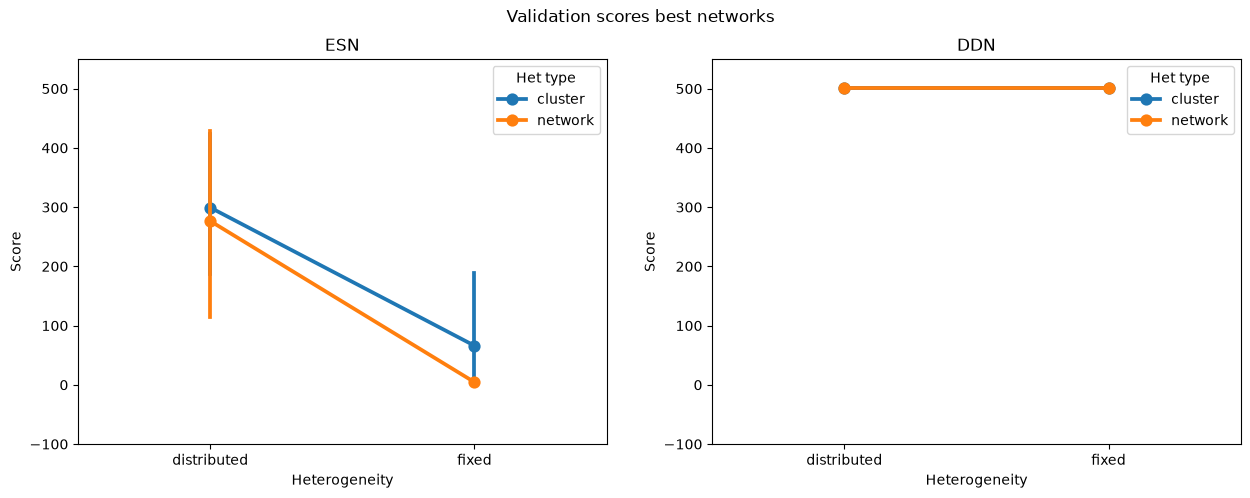

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
ax[0].set_title("ESN")
ax[1].set_title("DDN")
fig.suptitle("Validation scores best networks")
sns.pointplot(ax=ax[0], data=best_val_results_bl, x="Heterogeneity", y="Score", hue="Het type")
sns.pointplot(ax=ax[1], data=best_val_results_ddn, x="Heterogeneity", y="Score", hue="Het type")
ax[0].set_ylim(-100, 550)
ax[1].set_ylim(-100, 550)

## Test Results
Same as above, but with the test results. The test-validation gap should be minimal, since this uses synthetic data without noise. There should be no overfitting.

First, import test data, obtained from running [testOptimized_MG.py](testOptimized_MG.py)

In [10]:
maxgen = 150

# test_results_dir = Path("2026-analyses/heterogeneity_results_MG/")
test_results_dir = Path("C:/Users/Nishant Joshi/DDN_dynamics/DDN-public/test_results_MG")
for net_type in MG_imports:
    for heterogeneity in MG_imports[net_type]:
        for het_type in MG_imports[net_type][heterogeneity]:
            exp_filename = str(MG_imports[net_type][heterogeneity][het_type]['path'].name)
            test_filename = exp_filename[:-2] + "_gen150_test_optimized.p"
            test_filename = exp_filename[:-2] + "_gen150_test_optimized.p"
            test_path = test_results_dir/test_filename
            with open(test_path, 'rb') as file:
                test_dict = pkl.load(file)
            MG_imports[net_type][heterogeneity][het_type]['test_dict'] = test_dict

### Test Results for each tau separately

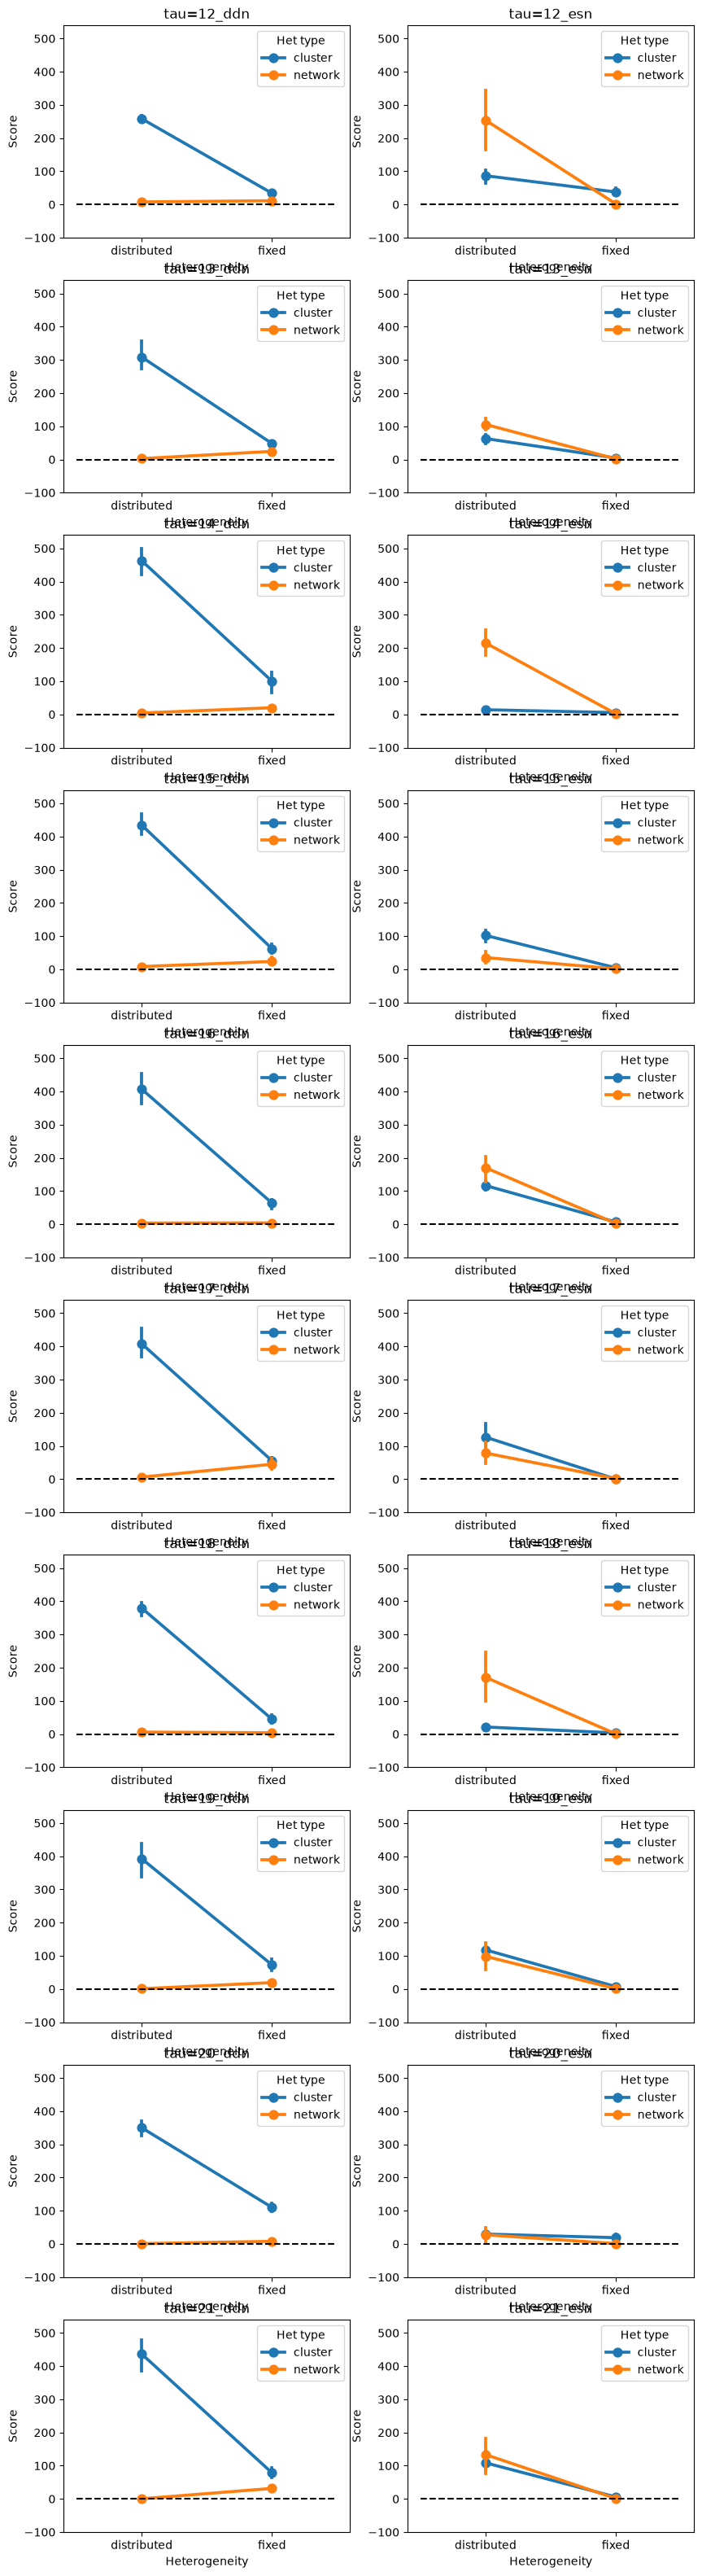

In [15]:
# taus = MG_imports[net_type][heterogeneity][het_type]['results_dict']["tau list"]
tau_range = MG_imports[net_type][heterogeneity][het_type]['results_dict']["tau range"]
taus = range(tau_range[0], tau_range[1])
fig, axs = plt.subplots(len(taus),2, figsize=(10, 40))

for plot_i, tau in enumerate(taus):
    
    test_results_all = {
        'ddn': 
            {
                "Heterogeneity": [],
                "Het type": [],
                "Score": []
            },
        'esn': 
            {
                "Heterogeneity": [],
                "Het type": [],
                "Score": []
            }
    }
    

    for plot_j, net_type in enumerate(MG_imports):
        for heterogeneity in MG_imports[net_type]:
            for het_type in MG_imports[net_type][heterogeneity]:
                test_dict = MG_imports[net_type][heterogeneity][het_type]['test_dict']
                test_scores = list(np.array(test_dict[tau]).flatten())
                test_results_all[net_type]['Score'] += test_scores
                test_results_all[net_type]['Heterogeneity'] += [heterogeneity] * len(test_scores)
                test_results_all[net_type]['Het type'] += [het_type] * len(test_scores)
        

        sns.pointplot(ax=axs[plot_i, plot_j], data=test_results_all[net_type], x="Heterogeneity", y="Score", hue="Het type")
        axs[plot_i, plot_j].set_title("tau=" + str(tau) + "_" + net_type)
        axs[plot_i, plot_j].hlines(y=0, xmin=-0.5, xmax=1.5, colors='k', linestyles='--')
        axs[plot_i, plot_j].set_ylim(-100, 540)

Now with tau on the horizontal axis

In [12]:
taus = MG_imports[net_type][heterogeneity][het_type]['results_dict']["tau list"]
# tau_range = MG_imports[net_type][heterogeneity][het_type]['results_dict']["tau range"]
# taus = range(tau_range[0], tau_range[1])
fig, axs = plt.subplots(2,1, figsize=(10, 8))
test_results_all = {
    'ddn': 
        {
            "Het type": [],
            "Score": [],
            "Tau": []
        },
    'esn': 
        {
            "Het type": [],
            "Score": [],
            "Tau": []
        }
}


for plot_j, net_type in enumerate(MG_imports):
    for heterogeneity in MG_imports[net_type]:
        for plot_i, tau in enumerate(taus):    
            for het_type in MG_imports[net_type][heterogeneity]:
                test_dict = MG_imports[net_type][heterogeneity][het_type]['test_dict']
                test_scores = list(np.array(test_dict[tau]).flatten())
                test_results_all[net_type]['Score'] += test_scores
                ht = heterogeneity + "_" + het_type
                test_results_all[net_type]['Het type'] += [ht] * len(test_scores)
                test_results_all[net_type]['Tau'] += [tau] * len(test_scores)
        

    sns.pointplot(ax=axs[plot_j], data=test_results_all[net_type], x="Tau", y="Score", hue="Het type")
    axs[plot_j].set_title(net_type)
    axs[plot_j].set_ylim(0, 540)
    plt. tight_layout()

KeyError: 'tau list'

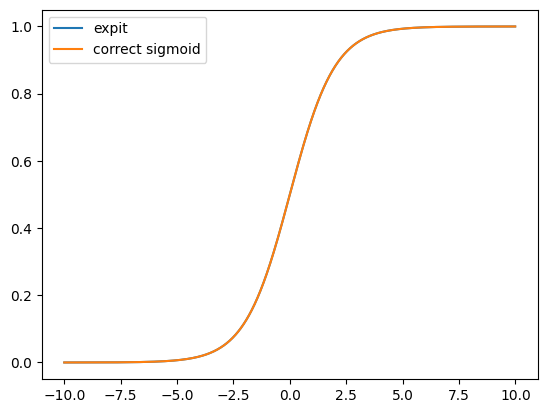

In [ ]:
# Temp cell, remove
import numpy as np
from scipy.special import expit
import matplotlib.pyplot as plt
from network import sigmoid_activation

def correct_sigmoid(x):
    y = 1 / (1 + np.exp(-x))
    return y

x = np.arange(-10, 10, .01)
y_1 = expit(x)
y_2 = expit(expit(x))
y_3 = sigmoid_activation(x)
y_4 = correct_sigmoid(x)

plt.plot(x, y_1, label="expit")
# plt.plot(x, y_2, label="double expit")
# plt.plot(x, y_3, label="used activation function")
plt.plot(x, y_4, label="correct sigmoid")
plt.legend()

# Numerical Jacobian estimation
First let's take an example network

In [ ]:
from testOptimized_MG import resample_net_MG_best
from simulator import NetworkSimulator


example_net_J = resample_net_MG_best(MG_imports["ddn"]["distributed"]["cluster"]['results_dict'])
sim = NetworkSimulator(example_net_J)
input_sequence = np.random.uniform(0, 1, size=(400))
warmup_sequence = np.random.uniform(0, 1, size=(100))
eps = 1e-6

sim.warmup(warmup_sequence)

states = sim.get_network_data(input_sequence)
print(states.shape)

(119, 400)


In [ ]:
def jacobian_fd(network, u, eps=1e-5):
    """
    Compute the Jacobian of the RNN hidden state w.r.t. previous hidden state using finite differences.

    Parameters:
    net    : network, RNN step, takes (h_prev, x) -> h_next
    h_prev : np.array, shape (n,), previous hidden state
    u      : np.array, input at this timestep
    eps    : float, small perturbation for finite differences

    Returns:
    J      : np.array, shape (m, n), Jacobian matrix
    """
    
    state_prev = network.A
    state_next = network.update_step(input)

    n = h_prev.shape[0]        # size of previous hidden state (input dimension)
    h_next = f(h_prev, x)
    m = h_next.shape[0]        # size of current hidden state (output dimension)

    J = np.zeros((m, n))       # initialize Jacobian matrix

    for i in range(n):
        e = np.zeros_like(h_prev)  # perturbation vector, same size as h_prev
        e[i] = 1.0                 # perturb only the i-th element

        h_plus  = f(h_prev + eps * e, x)   # forward perturbation
        h_minus = f(h_prev - eps * e, x)   # backward perturbation

        J[:, i] = (h_plu

(119,)
0.13962895466968117
(119,)
0.25676604737134334
(119,)
0.009169437440762818
(119,)
0.0656372935514089
(119,)
0.3083064314738162
(119,)
0.16163036531689323
(119,)
0.9811650076173073
(119,)
0.7145018588641958
(119,)
0.45753156697794206
(119,)
0.6550497998349101
(119,)
0.8378781775909565
(119,)
0.5811446727796382
(119,)
0.39764190410002354
(119,)
0.6779407103128771
(119,)
0.9395131676986594
(119,)
0.7835872320094853
(119,)
0.05222113158355701
(119,)
0.31833842000523327
(119,)
0.8949421685710454
(119,)
0.46820315676047364
(119,)
0.9257275933611687
(119,)
0.6511024723713071
(119,)
0.7930724340835494
(119,)
0.42506657782290425
(119,)
0.8184591472054427
(119,)
0.6344961420948974
(119,)
0.6239998560488065
(119,)
0.7439488048528113
(119,)
0.7256350097418027
(119,)
0.38027752609955146
(119,)
0.7161258797309789
(119,)
0.9123885282915271
(119,)
0.23401071023698683
(119,)
0.7524146634115735
(119,)
0.5344904209972768
(119,)
0.6592560883821822
(119,)
0.9276203490377332
(119,)
0.5488464864204148